### All imports

In [ ]:
!pip install control
import control as ct

from IPython.display import clear_output
clear_output()

In [ ]:
import numpy as np

from sympy import symbols, rad, solve, lambdify, Matrix, matrix2numpy
from sympy.physics.mechanics import ReferenceFrame, dynamicsymbols

from scipy.integrate import odeint

from matplotlib import pyplot as plt

from matplotlib.animation import FFMpegWriter
from IPython.display import Image

### Kinematics

In [65]:
x_1, x_2, theta = dynamicsymbols('x_1, x_2, theta')
u_1, u_2 = symbols('u_1, u_2')

N = ReferenceFrame('N')

B = N.orientnew('B', 'Axis', (theta, N.z))
M = B.orientnew('M', 'Axis', (rad(90) + u_2, B.z))

xipos = x_1*N.x + x_2*N.y
xivel = xipos.dt(N)
xiacc = xivel.dt(N)

### Kinetics

In [86]:
m, l, c = symbols('m, l, c')

sumF = u_1*M.x -c*(xivel) -m*9.81*N.y - m*xiacc

sumM = (-l/2*B.y).cross(u_1*M.x) -c*theta.diff()*B.z - m*l**2/12*theta.diff().diff()*B.z


In [87]:
sumFx = sumF.dot(N.x)
sumFy = sumF.dot(N.y)
sumMz = sumM.dot(N.z)

eqs = [sumFx, sumFy, sumMz]
vars = [x_1.diff().diff(), x_2.diff().diff(), theta.diff().diff()]

slns = solve(eqs, vars)

acc = Matrix([slns[x_1.diff().diff()], slns[x_2.diff().diff()], slns[theta.diff().diff()]])
acc.simplify()

In [88]:
params = {c: 0.5, m: 5, l:1}
xddot = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()], u_1, u_2], acc.subs(params), 'numpy')

### ODE Solution

In [89]:
def odefun(q, t, u_1, u_2):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]
  qdot[3:] = xddot(q, u_1, u_2).squeeze()
  return qdot

In [94]:
dt = 1/10000
time = np.arange(0, 10, dt)
q0 = np.array([0, 0, 0, 0, 0, 0])

q_list = odeint(odefun, q0, time, args=(36, np.deg2rad(0)))

In [95]:
def makeAnimation(qq, dt, filename='anim.gif', FPS=24, dpi=80, window_size=10):
  xipos_x = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], xipos.dot(N.x).subs(params))
  xipos_y = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], xipos.dot(N.y).subs(params))

  motor_pos_x = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], (xipos -l/2*B.y).dot(N.x).subs(params))
  motor_pos_y = lambdify([[x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]], (xipos -l/2*B.y).dot(N.y).subs(params))

  fig, ax = plt.subplots()
  com = ax.scatter([], [], label='com')
  motor = ax.scatter([],[], label='motor')

  ax.grid()
  ax.legend()
  ax.set_xlim(-window_size, window_size)
  ax.set_ylim(-window_size, window_size)
  ax.set_aspect('equal')

  ax.set(xlabel='$x$ Axis ($m$)', ylabel='$y$ Axis ($m$)')


  sample_rate = int(1/(dt*FPS))
  writer = FFMpegWriter(fps=FPS)

  with writer.saving(fig, filename, dpi):
    for i in range(0, len(qq), sample_rate):

      com.set_offsets([[xipos_x(qq[i]), xipos_y(qq[i])]])
      motor.set_offsets([[motor_pos_x(qq[i]), motor_pos_y(qq[i])]])

      fig.canvas.draw()
      writer.grab_frame()

  plt.close(fig)

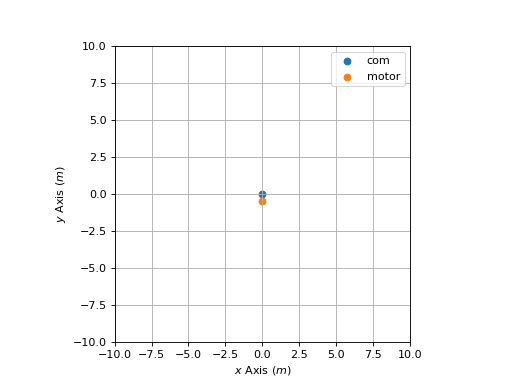

In [96]:
makeAnimation(q_list, dt)

gif_display = Image(filename='anim.gif')
display(gif_display)

### State feedback

In [97]:
systemDynamics = Matrix([x_1.diff(), x_2.diff(), theta.diff(), slns[x_1.diff().diff()], slns[x_2.diff().diff()], slns[theta.diff().diff()]])
systemDynamics.simplify()

In [98]:
x = [x_1, x_2, theta, x_1.diff(), x_2.diff(), theta.diff()]
u = [u_1, u_2]

x_star = {x_1:0, x_2:0, theta:rad(0), x_1.diff():0, x_2.diff():0, theta.diff():0}
u_star = {u_1:5*9.81, u_2:rad(0)}

systemDynamics.subs(x_star | u_star)

Matrix([
[                 0],
[                 0],
[                 0],
[                 0],
[(49.05 - 9.81*m)/m],
[                 0]])

In [100]:
A = systemDynamics.jacobian(x).subs(x_star | u_star)
A.simplify()
display(A)
A = A.subs(params)

Matrix([
[0, 0,        0,    1,        0,                0],
[0, 0,        0,    0,        1,                0],
[0, 0,        0,    0,        0,                1],
[0, 0, -49.05/m, -c/m,        0,                0],
[0, 0,        0,    0, -1.0*c/m,                0],
[0, 0,        0,    0,        0, -12.0*c/(l**2*m)]])

In [101]:
Bmat = systemDynamics.jacobian(u).subs(x_star | u_star)
Bmat.simplify()
display(Bmat)
Bmat = Bmat.subs(params)

Matrix([
[    0,            0],
[    0,            0],
[    0,            0],
[    0,     -49.05/m],
[1.0/m,            0],
[    0, -294.3/(l*m)]])

In [102]:
Matrix([[Bmat, A@Bmat, (A@A)@Bmat, (A@(A@A))@Bmat, (A@(A@(A@A)))@Bmat, (A@(A@(A@(A@A))))@Bmat]]).rank()

6

In [171]:
Q = np.eye(len(x))*10
R = np.eye(len(u))*0.1
k, S, E = ct.lqr(A, Bmat, Q, R)
k

array([[-6.85544728e-15,  1.00000000e+01,  5.85702867e-15,
        -2.75831513e-15,  1.36509717e+01,  5.24346122e-16],
       [ 1.00000000e+01, -4.90964815e-14, -6.18618868e+01,
         1.45010463e+01, -1.90197066e-14, -1.26303791e+01]])

In [172]:
(A-Bmat@k).eigenvals()

{-1.46509716980849 - 2.13493280201935e-63*I: 1,
 -1.36509716980849 + 1.83085892009756e-63*I: 1,
 -2.37608689737893 - 2.00767858195152*I: 1,
 -0.999999993308138 + 6.71318220506672e-64*I: 1,
 -2.37608689737893 + 2.00767858195152*I: 1,
 -596.716674786874: 1}

In [173]:
C = Matrix([[0, 0, 1.1, 0, 0, 0],
              [0, 0, 0, 0, 1, 0]])
(C @ (-(A-Bmat@k)).inv() @ Bmat).rank()

1

In [174]:
def odefun2(q, t):
  qdot = np.zeros_like(q)
  qdot[:3] = q[3:]

  u = -k@(q)*10

  qdot[3:] = xddot(q, u[0], u[1]).squeeze()
  return qdot

In [ ]:
dt = 1/(5*1000)
time = np.arange(0, 5, dt)
q0 = np.array([0.5, 0.5, 0, 0, 0, 0])

q_list = odeint(odefun2, q0, time)

In [176]:
q_list

array([[ 1.00000000e+00,  1.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 1.00000032e+00,  9.99999654e-01,  1.90988425e-06,
         3.25238942e-03, -2.17931912e-03,  1.95122422e-02],
       [ 1.00000109e+00,  9.99999396e-01,  6.55806551e-06,
         4.16649581e-03, -3.04386175e-04,  2.49918645e-02],
       ...,
       [ 1.20709221e-08, -1.38006713e+00, -1.09059456e-09,
        -1.20635496e-08, -9.41297771e-02,  1.04907216e-09],
       [ 1.20685097e-08, -1.38008595e+00, -1.09038483e-09,
        -1.20611478e-08, -9.41194165e-02,  1.04889221e-09],
       [ 1.20660978e-08, -1.38010477e+00, -1.09017513e-09,
        -1.20587465e-08, -9.41090570e-02,  1.04871229e-09]])

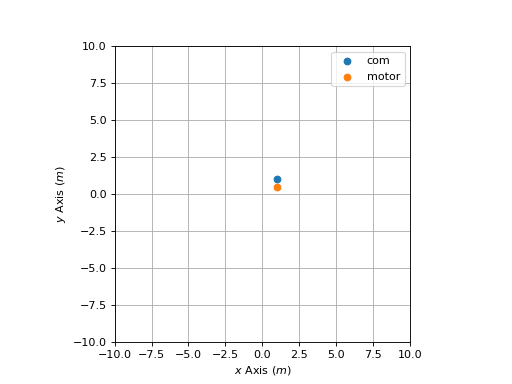

In [177]:
makeAnimation(q_list, dt, window_size=10)

gif_display = Image(filename='anim.gif')
display(gif_display)